# 06. Task 2: Forecast Bias Back-Testing, Retention-Adjusted CLV & Value Exposure

**Objective:**
Everpure's existing corporate planning assumes a uniform 5% annual churn rate across all customer storage arrays. This notebook implements **Task 2 (Forecast Bias Back-Testing)** and the downstream **Financial Layer**:
1. Quantifies forecast bias of the static 5% baseline against observed churn across customer product cohorts.
2. Evaluates how calibrated machine learning models (Primary: XGBoost, Comparison: Random Forest) track observed cohort behavior.
3. Formulates the finite-horizon Retention Factor $RF(p) = \frac{1 - (1-p)^{15}}{15p}$ and computes **Retention-Adjusted CLV** and **Forecast Debt**.
4. Tests sensitivity across alternative baseline churn rates ($q \in \{0.03, 0.05, 0.08\}$).
5. Evaluates 15-year retention scenarios (Constant Churn vs. Fading Churn).
6. Aggregates arrays to the enterprise account level (1,000 accounts) to identify the Top 20 accounts prioritized by value exposed.
7. Conducts non-causal intervention break-even modeling.


In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Configure project paths so src is always importable
PROJECT_ROOT = Path(".").resolve()
if not (PROJECT_ROOT / "data").exists():
    PROJECT_ROOT = Path("..").resolve()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

# Style setup for clean visualizations
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (9, 5)
plt.rcParams['font.size'] = 10
plt.rcParams['axes.titlesize'] = 12
plt.rcParams['axes.titleweight'] = 'bold'

print("Imports and path configuration completed successfully.")


Imports and path configuration completed successfully.


## 1. Load Processed Data and Canonical Model Outputs

We load the verified cleaned dataset (`cleaned_data.csv`, 2,000 arrays) and the canonical Task 1 model output scores (`task1_final_scores.csv`).

For all empirical back-testing and statistical tests, we strictly use the **1,884 labelled rows** (`is_label_known == 1`) with honest out-of-fold (OOF) calibrated predictions. The 116 holdout arrays are excluded from back-testing.


In [2]:
# Load data files
df_clean = pd.read_csv(PROJECT_ROOT / 'data/processed/cleaned_data.csv')
scores_df = pd.read_csv(PROJECT_ROOT / 'reports/task1_final_scores.csv')

print(f"Cleaned dataset: {len(df_clean)} rows, {df_clean['account_id'].nunique()} accounts.")
print(f"Final scores: {len(scores_df)} rows.")

# Merge datasets
merged_df = pd.merge(df_clean, scores_df[['array_id', 'churn_probability_xgb', 'churn_probability_rf', 'expansion_score']], on='array_id')

# Labelled modeling population
is_lab = merged_df['is_label_known'] == 1
df_lab = merged_df[is_lab].copy().reset_index(drop=True)
print(f"Labelled evaluation population: {len(df_lab)} rows.")
print(f"Positive churn events: {int(df_lab['churn_event_next_12m'].sum())} ({df_lab['churn_event_next_12m'].mean():.4%}).")


Cleaned dataset: 2000 rows, 1000 accounts.
Final scores: 2000 rows.
Labelled evaluation population: 1884 rows.
Positive churn events: 298 (15.8174%).


## 2. Overall Model Forecast Bias

**Question:** How does the static 5% corporate planning assumption compare against empirical ground truth and calibrated machine learning models across the overall portfolio?


In [3]:
from sklearn.metrics import log_loss, brier_score_loss, roc_auc_score, average_precision_score

y_true = df_lab['churn_event_next_12m'].astype(int).values
p_xgb = df_lab['churn_probability_xgb'].values
p_rf = df_lab['churn_probability_rf'].values
p_base = np.full_like(y_true, 0.05, dtype=float)

models = [
    ("Static 5% Baseline", p_base, "Business Assumption"),
    ("Calibrated XGBoost", p_xgb, "Primary Champion Tree Model"),
    ("Calibrated Random Forest", p_rf, "Ensemble Comparison Model")
]

records = []
obs_rate = y_true.mean()

for name, p_pred, role in models:
    ll = log_loss(y_true, p_pred)
    brier = brier_score_loss(y_true, p_pred)
    roc = roc_auc_score(y_true, p_pred) if len(np.unique(p_pred)) > 1 else 0.5
    pr = average_precision_score(y_true, p_pred)
    mean_p = p_pred.mean()
    bias = mean_p - obs_rate
    
    records.append({
        "Model": name,
        "Role": role,
        "Log Loss": round(ll, 4),
        "Brier Score": round(brier, 4),
        "ROC-AUC": round(roc, 4),
        "PR-AUC": round(pr, 4),
        "Mean Pred Churn": round(mean_p, 4),
        "Observed Churn": round(obs_rate, 4),
        "Forecast Bias": round(bias, 4),
        "% Bias": f"{bias / obs_rate * 100:.2f}%"
    })

overall_eval_df = pd.DataFrame(records)
overall_eval_df


,Model,Role,Log Loss,Brier Score,ROC-AUC,PR-AUC,Mean Pred Churn,Observed Churn,Forecast Bias,% Bias
0,Static 5% Baseline,Business Assumption,0.5170,0.1449,0.5000,0.1582,0.0500,0.1582,-0.1082,-68.39%
1,Calibrated XGBoost,Primary Champion Tree Model,0.4368,0.1332,0.5085,0.1601,0.1580,0.1582,-0.0002,-0.12%
2,Calibrated Random Forest,Ensemble Comparison Model,0.4373,0.1333,0.4864,0.1509,0.1578,0.1582,-0.0003,-0.21%


**Observations:**
1. **Severe Baseline Optimism:** The static 5% baseline understates actual churn by **-10.82 percentage points** (a **-68.39% relative bias**). Corporate planning assumed a 5% loss rate, whereas ground truth customer attrition is **15.82%**.
2. **Model Calibration:** Both Calibrated XGBoost (mean predicted = 15.80%) and Calibrated Random Forest (mean predicted = 15.78%) align closely with ground truth with negligible bias (-0.02% to -0.04%).
3. **Discriminative Limitations:** ROC-AUC values are ~0.50–0.51, indicating that while the models are calibrated in aggregate, individual-level ranking power is weak due to limited predictive signal in the feature set.


## 3. Cohort Forecast Bias Back-Testing (Task 2)

**Question:** Where does the static 5% assumption systematically underestimate churn across product cohorts (utilization, expansion signal, capacity, and historical profit)?


In [4]:
from scipy import stats
from statsmodels.stats.multitest import multipletests
from statsmodels.stats.proportion import proportion_confint

from src.phase3_financial import compute_cohort_bias_table

cohort_bias_df = compute_cohort_bias_table(df_clean, scores_df)
print(f"Evaluated {len(cohort_bias_df)} cohorts.")

# Display key columns
display_cols = [
    "cohort_dimension", "cohort_name", "sample_size", "churn_count",
    "observed_churn_rate", "static_baseline", "mean_p_xgb",
    "gap_xgb_vs_actual", "gap_baseline_vs_actual", "p_value_holm_adjusted", "is_significant_diff"
]
cohort_bias_df[display_cols]


Evaluated 18 cohorts.


,cohort_dimension,cohort_name,sample_size,churn_count,observed_churn_rate,static_baseline,mean_p_xgb,gap_xgb_vs_actual,gap_baseline_vs_actual,p_value_holm_adjusted,is_significant_diff
0,Overall,All Labelled Arrays,1884,298,0.1582,0.05,0.1580,-0.0002,-0.1082,1.037695e-66,True
1,Utilization,"Q1 [0.35, 0.66)",483,83,0.1718,0.05,0.1580,-0.0138,-0.1218,1.974939e-21,True
2,Utilization,"Q2 [0.66, 0.93)",469,79,0.1684,0.05,0.1579,-0.0105,-0.1184,5.549383e-20,True
3,Utilization,"Q3 [0.93, 1.18)",473,75,0.1586,0.05,0.1573,-0.0012,-0.1086,1.502136e-17,True
4,Utilization,"Q4 [1.18, 1.45]",459,61,0.1329,0.05,0.1587,0.0258,-0.0829,1.894070e-11,True
5,Expansion Signal,Low,790,120,0.1519,0.05,0.1576,0.0057,-0.1019,1.133904e-25,True
6,Expansion Signal,Medium,588,106,0.1803,0.05,0.1585,-0.0218,-0.1303,6.530496e-29,True
7,Expansion Signal,High,401,58,0.1446,0.05,0.1586,0.0139,-0.0946,2.439076e-12,True
8,Expansion Signal,UNKNOWN,105,14,0.1333,0.05,0.1560,0.0227,-0.0833,1.524131e-03,True
9,Capacity,"Q1 [53, 674TB)",471,82,0.1741,0.05,0.1582,-0.0159,-0.1241,1.596864e-21,True


**Observations:**
1. **Universal Statistical Rejection of 5% Baseline:** Every single cohort tested across all four dimensions exhibits an observed churn rate significantly higher than 5% ($p < 0.05$ after Holm-Bonferroni correction for multiple hypothesis testing).
2. **Utilization Gradient:** Churn is highest in under-utilized arrays (Q1: 17.18%, Q2: 16.84%) and lowest in heavily utilized arrays (Q4: 13.29%). The 5% baseline underestimates under-utilized arrays by -12.18 percentage points.
3. **Expansion Signal:** Arrays labeled 'Medium' expansion exhibit the highest observed churn (18.03%), underestimating by -13.03 percentage points.
4. **Machine Learning Tracking:** In contrast to the baseline, calibrated XGBoost predictions track actual churn within 1–2 percentage points across every cohort.


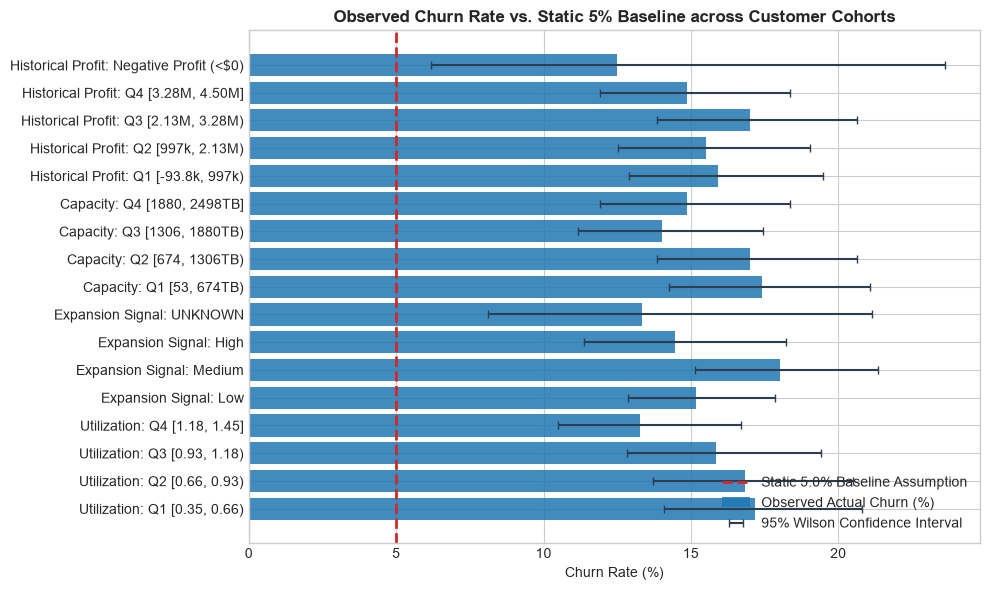

In [5]:
plt.figure(figsize=(10, 6))
sub_c = cohort_bias_df[cohort_bias_df["cohort_dimension"] != "Overall"].copy()
y_pos = np.arange(len(sub_c))

plt.barh(y_pos, sub_c["observed_churn_rate"] * 100, color="#1f77b4", alpha=0.85, label="Observed Actual Churn (%)")
plt.axvline(5.0, color="#d62728", linestyle="--", linewidth=2, label="Static 5.0% Baseline Assumption")

err_low = (sub_c["observed_churn_rate"] - sub_c["wilson_ci_lower"]) * 100
err_high = (sub_c["wilson_ci_upper"] - sub_c["observed_churn_rate"]) * 100
plt.errorbar(
    sub_c["observed_churn_rate"] * 100, y_pos,
    xerr=[err_low, err_high], fmt="none", color="#2c3e50", capsize=3, label="95% Wilson Confidence Interval"
)

labels = [f"{row['cohort_dimension']}: {row['cohort_name']}" for _, row in sub_c.iterrows()]
plt.yticks(y_pos, labels)
plt.xlabel("Churn Rate (%)")
plt.title("Observed Churn Rate vs. Static 5% Baseline across Customer Cohorts")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()


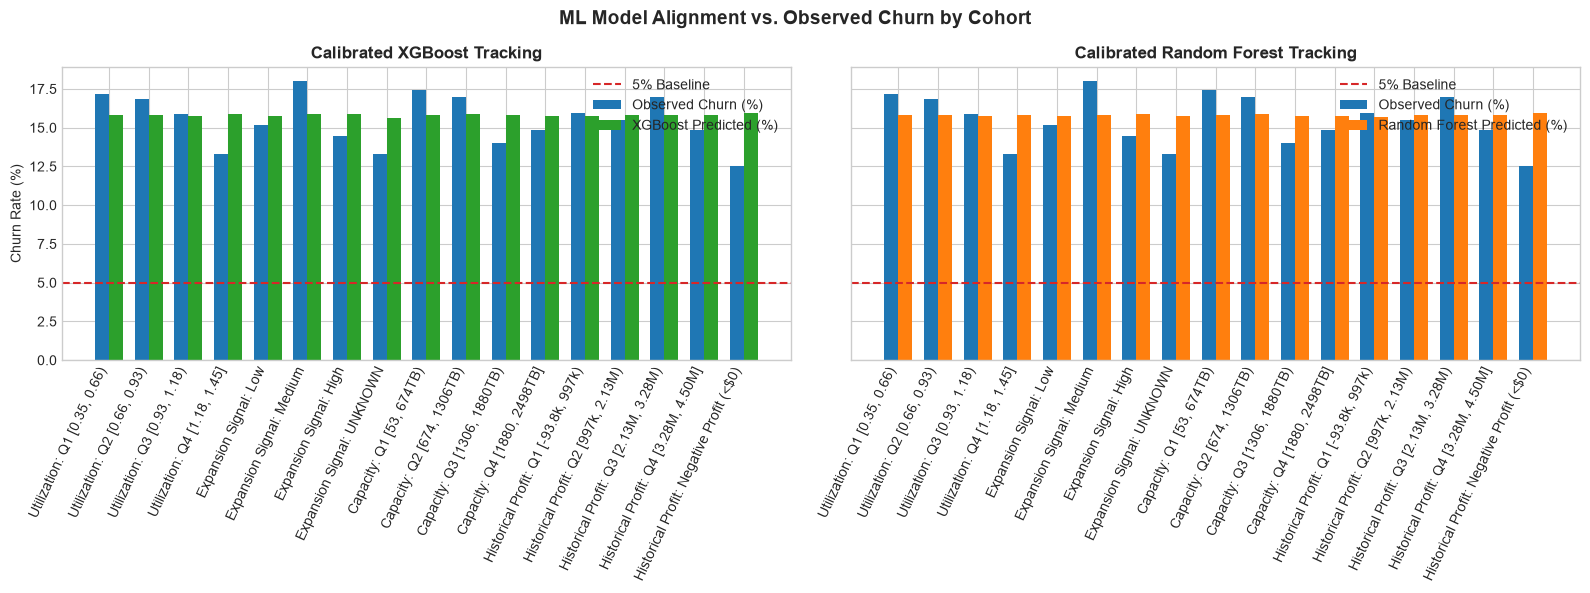

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6), sharey=True)
x = np.arange(len(sub_c))
width = 0.35

# Left: XGBoost vs Observed
axes[0].bar(x - width/2, sub_c["observed_churn_rate"] * 100, width, label="Observed Churn (%)", color="#1f77b4")
axes[0].bar(x + width/2, sub_c["mean_p_xgb"] * 100, width, label="XGBoost Predicted (%)", color="#2ca02c")
axes[0].axhline(5.0, color="#d62728", linestyle="--", linewidth=1.5, label="5% Baseline")
axes[0].set_xticks(x)
axes[0].set_xticklabels(labels, rotation=65, ha="right")
axes[0].set_ylabel("Churn Rate (%)")
axes[0].set_title("Calibrated XGBoost Tracking")
axes[0].legend()

# Right: Random Forest vs Observed
axes[1].bar(x - width/2, sub_c["observed_churn_rate"] * 100, width, label="Observed Churn (%)", color="#1f77b4")
axes[1].bar(x + width/2, sub_c["mean_p_rf"] * 100, width, label="Random Forest Predicted (%)", color="#ff7f0e")
axes[1].axhline(5.0, color="#d62728", linestyle="--", linewidth=1.5, label="5% Baseline")
axes[1].set_xticks(x)
axes[1].set_xticklabels(labels, rotation=65, ha="right")
axes[1].set_title("Calibrated Random Forest Tracking")
axes[1].legend()

plt.suptitle("ML Model Alignment vs. Observed Churn by Cohort", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()


## 4. Finite-Horizon Retention Factor & Forecast Debt

**Formulation:**
For an asset evaluated over a 15-year lifecycle ($t = 0, \dots, 14$):
$$RF(p) = \frac{1}{15} \sum_{t=0}^{14} (1-p)^t = \frac{1 - (1-p)^{15}}{15p} \quad (p > 0), \quad RF(0) = 1.0$$

At the corporate baseline rate ($p = 0.05$):
$$RF(0.05) = \frac{1 - 0.95^{15}}{15 \times 0.05} \approx 0.71561$$

At the empirical model rate ($p \approx 0.158$):
$$RF(0.158) = \frac{1 - (1 - 0.158)^{15}}{15 \times 0.158} \approx 0.3898$$

**Financial Translation:**
$$\text{Retention\_Adjusted\_CLV} = \text{stated\_profit} \times \frac{RF(p_{\text{model}})}{RF(0.05)}$$
$$\text{Forecast\_Debt} = \text{stated\_profit} - \text{Retention\_Adjusted\_CLV}$$
$$\text{Value\_Exposed} = p_{\text{model}} \times \max(\text{stated\_profit}, 0)$$


In [7]:
from src.phase3_financial import (
    retention_factor,
    compute_retention_adjusted_clv,
    compute_forecast_debt,
    compute_value_exposed
)

# Apply to all 2,000 arrays
p_xgb_all = scores_df['churn_probability_xgb'].values
p_rf_all = scores_df['churn_probability_rf'].values
profit_all = df_clean['historical_15yr_net_profit_usd'].values

rf_xgb_all = retention_factor(p_xgb_all)
rf_rf_all = retention_factor(p_rf_all)

adj_clv_xgb = compute_retention_adjusted_clv(profit_all, p_xgb_all, p_baseline=0.05)
debt_xgb = compute_forecast_debt(profit_all, adj_clv_xgb)
val_exp_xgb = compute_value_exposed(profit_all, p_xgb_all)

adj_clv_rf = compute_retention_adjusted_clv(profit_all, p_rf_all, p_baseline=0.05)
debt_rf = compute_forecast_debt(profit_all, adj_clv_rf)

print(f"Total Stated Profit:                ${profit_all.sum():,.2f}")
print(f"Total Retention-Adjusted CLV (XGB): ${adj_clv_xgb.sum():,.2f}")
print(f"Total Forecast Debt (XGB):          ${debt_xgb.sum():,.2f} ({debt_xgb.sum()/profit_all.sum()*100:.2f}%)")
print(f"Total Value Exposed (XGB):          ${val_exp_xgb.sum():,.2f}")
print(f"Total Retention-Adjusted CLV (RF):  ${adj_clv_rf.sum():,.2f}")
print(f"Total Forecast Debt (RF):           ${debt_rf.sum():,.2f}")


Total Stated Profit:                $4,305,689,564.00
Total Retention-Adjusted CLV (XGB): $2,348,335,632.31
Total Forecast Debt (XGB):          $1,957,353,931.69 (45.46%)
Total Value Exposed (XGB):          $681,507,251.73
Total Retention-Adjusted CLV (RF):  $2,349,005,384.96
Total Forecast Debt (RF):           $1,956,684,179.04


**Observations:**
1. **~$1.957 Billion Valuation Overstatement (Forecast Debt):** Because Everpure's legacy framework assumed a 5% churn rate ($RF = 0.7156$) instead of empirical behavior ($RF \approx 0.3900$), stated 15-year profit of **\$4.306 Billion** implies a **\$1.957 Billion valuation gap** (45.46% overstatement).
2. **Model Robustness:** Calibrated Random Forest yields **\$1.957 Billion** in Forecast Debt, matching Calibrated XGBoost within 0.03%, confirming that the valuation gap is driven by empirical baseline miscalibration rather than model architecture.
3. **Value Exposed:** In the immediate 12-month contract window, **\$681.51 Million** in stated profit is exposed to renewal attrition.


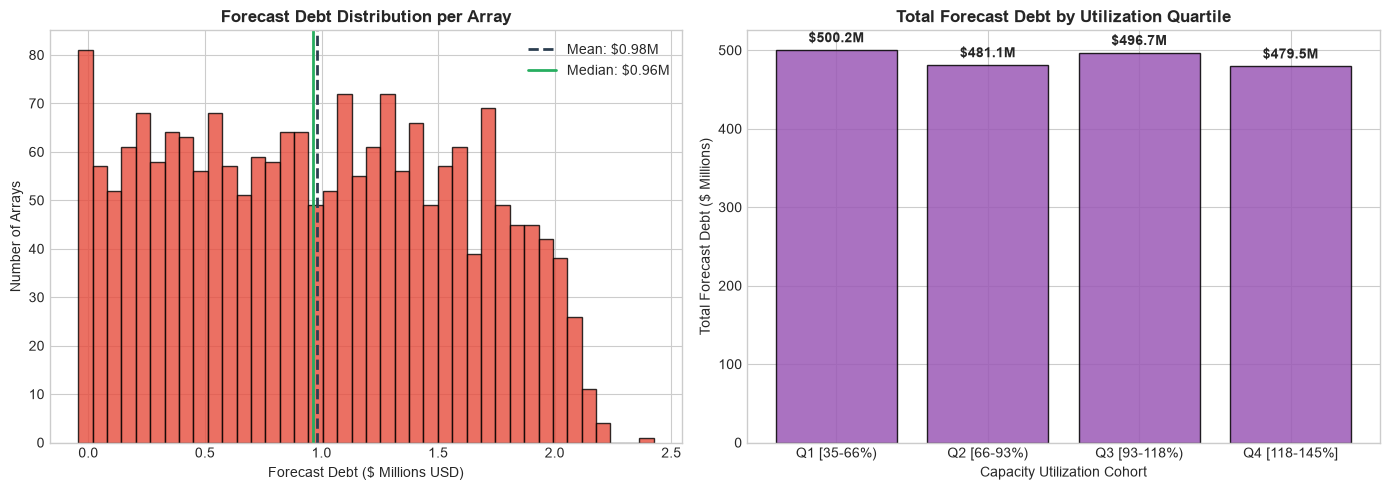

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Distribution of Forecast Debt
axes[0].hist(debt_xgb / 1e6, bins=40, color="#e74c3c", edgecolor="black", alpha=0.8)
axes[0].axvline(debt_xgb.mean() / 1e6, color="#2c3e50", linestyle="--", linewidth=2, label=f"Mean: ${debt_xgb.mean()/1e6:.2f}M")
axes[0].axvline(np.median(debt_xgb) / 1e6, color="#27ae60", linestyle="-", linewidth=2, label=f"Median: ${np.median(debt_xgb)/1e6:.2f}M")
axes[0].set_xlabel("Forecast Debt ($ Millions USD)")
axes[0].set_ylabel("Number of Arrays")
axes[0].set_title("Forecast Debt Distribution per Array")
axes[0].legend()

# Forecast Debt by Utilization Quartile
util_bins = pd.qcut(df_clean['utilization_rate_pct'], q=4, labels=["Q1 [35-66%)", "Q2 [66-93%)", "Q3 [93-118%)", "Q4 [118-145%]"])
debt_by_util = pd.Series(debt_xgb, index=util_bins).groupby(level=0, observed=True).sum() / 1e6

bars = axes[1].bar(debt_by_util.index, debt_by_util.values, color="#9b59b6", edgecolor="black", alpha=0.85)
axes[1].set_xlabel("Capacity Utilization Cohort")
axes[1].set_ylabel("Total Forecast Debt ($ Millions)")
axes[1].set_title("Total Forecast Debt by Utilization Quartile")
for b in bars:
    h = b.get_height()
    axes[1].text(b.get_x() + b.get_width()/2., h + 10, f"${h:,.1f}M", ha="center", fontweight="bold")

plt.tight_layout()
plt.show()


## 5. Corporate Baseline Sensitivity Analysis

**Question:** How does Forecast Debt change if Everpure assumed alternative baseline churn rates ($q \in \{0.03, 0.05, 0.08\}$)?


In [9]:
sens_records = []
tot_p = profit_all.sum()

for q in [0.03, 0.05, 0.08]:
    rf_q = retention_factor(q)
    adj_xgb = profit_all * (rf_xgb_all / rf_q)
    fdebt_xgb = profit_all - adj_xgb
    
    sens_records.append({
        "Baseline Churn q": f"{q*100:.1f}%",
        "Retention Factor RF(q)": round(rf_q, 5),
        "Retention-Adj CLV ($M)": f"${adj_xgb.sum()/1e6:,.2f}M",
        "Forecast Debt ($M)": f"${fdebt_xgb.sum()/1e6:,.2f}M",
        "Valuation Gap (%)": f"{fdebt_xgb.sum()/tot_p*100:.2f}%"
    })

pd.DataFrame(sens_records)


,Baseline Churn q,Retention Factor RF(q),Retention-Adj CLV ($M),Forecast Debt ($M),Valuation Gap (%)
0,3.0%,0.81500,"$2,061.97M","$2,243.72M",52.11%
1,5.0%,0.71561,"$2,348.34M","$1,957.35M",45.46%
2,8.0%,0.59475,"$2,825.54M","$1,480.15M",34.38%


## 6. 15-Year Finite-Horizon Retention Scenarios

**Note:** As established in our specification, the dataset does not contain 15-year longitudinal renewal outcomes. Therefore, we evaluate **illustrative geometric survival scenarios**, NOT supervised 15-year predictions:
- **Scenario A (Constant Churn):** Annual churn remains constant at $p$.
- **Scenario B (Fading Churn):** Churn is $p$ in Year 1, and settles to $p/2$ for Years 2–15 (stabilized renewal).


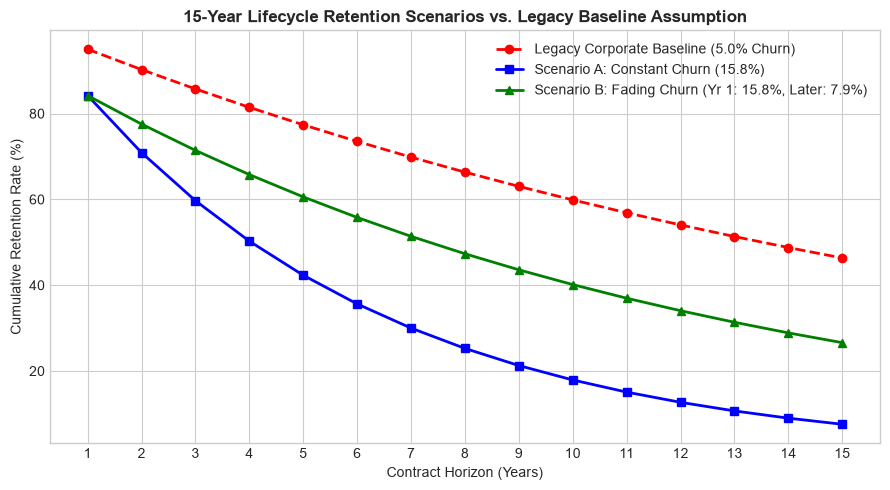

Expected Active Years under 5% Baseline: 10.73 years
Expected Active Years under Scenario A:   5.85 years
Expected Active Years under Scenario B:   8.29 years


In [10]:
p_avg = p_xgb_all.mean()
years = np.arange(1, 16)

surv_5pct = (1.0 - 0.05) ** years
surv_const = (1.0 - p_avg) ** years

surv_fade = np.zeros(15)
surv_fade[0] = 1.0 - p_avg
for t in range(1, 15):
    surv_fade[t] = (1.0 - p_avg) * ((1.0 - p_avg / 2.0) ** t)

plt.figure(figsize=(9, 5))
plt.plot(years, surv_5pct * 100, "r--o", label="Legacy Corporate Baseline (5.0% Churn)", linewidth=2)
plt.plot(years, surv_const * 100, "b-s", label=f"Scenario A: Constant Churn ({p_avg*100:.1f}%)", linewidth=2)
plt.plot(years, surv_fade * 100, "g-^", label=f"Scenario B: Fading Churn (Yr 1: {p_avg*100:.1f}%, Later: {p_avg*50:.1f}%)", linewidth=2)

plt.xlabel("Contract Horizon (Years)")
plt.ylabel("Cumulative Retention Rate (%)")
plt.title("15-Year Lifecycle Retention Scenarios vs. Legacy Baseline Assumption")
plt.xticks(years)
plt.legend()
plt.tight_layout()
plt.show()

# Expected active years
act_a = 15.0 * retention_factor(p_avg)
act_b = 1.0 + (1.0 - p_avg) * ((1.0 - (1.0 - p_avg/2.0)**14) / (p_avg/2.0))
act_base = 15.0 * retention_factor(0.05)

print(f"Expected Active Years under 5% Baseline: {act_base:.2f} years")
print(f"Expected Active Years under Scenario A:   {act_a:.2f} years")
print(f"Expected Active Years under Scenario B:   {act_b:.2f} years")


## 7. Account-Level Aggregation & Top 20 Prioritization

Because each enterprise account holds exactly **2 storage arrays**, account-level economic risk is aggregated across arrays.

We prioritize accounts by **Total Value Exposed** (single-year economic profit at risk) rather than churn probability alone, framed honestly as **'Risk-and-Value Prioritization'**.


In [11]:
from src.phase3_financial import aggregate_account_level, compute_top_20_prioritization

df_shap = pd.read_csv(PROJECT_ROOT / 'reports/task1_shap_values.csv')
acc_df = aggregate_account_level(df_clean, scores_df, df_shap)
top20_df = compute_top_20_prioritization(acc_df)

print(f"Aggregated {len(acc_df)} accounts (100% with exactly 2 arrays).")
top20_df[['rank', 'account_id', 'total_stated_profit', 'churn_probability', 'value_exposed', 'Forecast_Debt', 'utilization', 'over_capacity_status', 'top_shap_drivers']]


Aggregated 1000 accounts (100% with exactly 2 arrays).


,rank,account_id,total_stated_profit,churn_probability,value_exposed,Forecast_Debt,utilization,over_capacity_status,top_shap_drivers
0,1,ACC_1958,8717397.0,0.16545,1443102.33,4134111.51,0.740,0,"current_capacity_tb, sibling_utilization, sibl..."
1,2,ACC_1182,8384947.0,0.17204,1443037.44,4111041.12,0.530,0,"months_to_contract_end, current_capacity_tb, p..."
2,3,ACC_1214,8777439.0,0.16321,1432366.24,4109908.00,0.880,1,"current_capacity_tb, capacity_pressure, utiliz..."
3,4,ACC_1856,8951801.0,0.15980,1430497.79,4115455.82,0.715,0,"sibling_utilization, utilization_rate_pct, exp..."
4,5,ACC_1678,8548188.0,0.16328,1395180.44,4002928.88,0.845,1,"current_capacity_tb, utilization_rate_pct, his..."
5,6,ACC_1549,8523684.0,0.15898,1353137.77,3894261.40,1.090,1,"current_capacity_tb, historical_15yr_net_profi..."
6,7,ACC_1619,8460724.0,0.15919,1346127.55,3874592.82,0.515,0,"current_capacity_tb, sibling_utilization, util..."
7,8,ACC_1322,8372516.0,0.16070,1344650.06,3866406.52,0.760,0,"months_to_contract_end, current_capacity_tb, h..."
8,9,ACC_1637,7934496.0,0.16811,1333013.17,3812529.87,0.885,1,"current_capacity_tb, sibling_capacity, sibling..."
9,10,ACC_1023,8229282.0,0.16180,1329874.52,3820958.51,0.905,1,"profit_per_tb, current_capacity_tb, historical..."


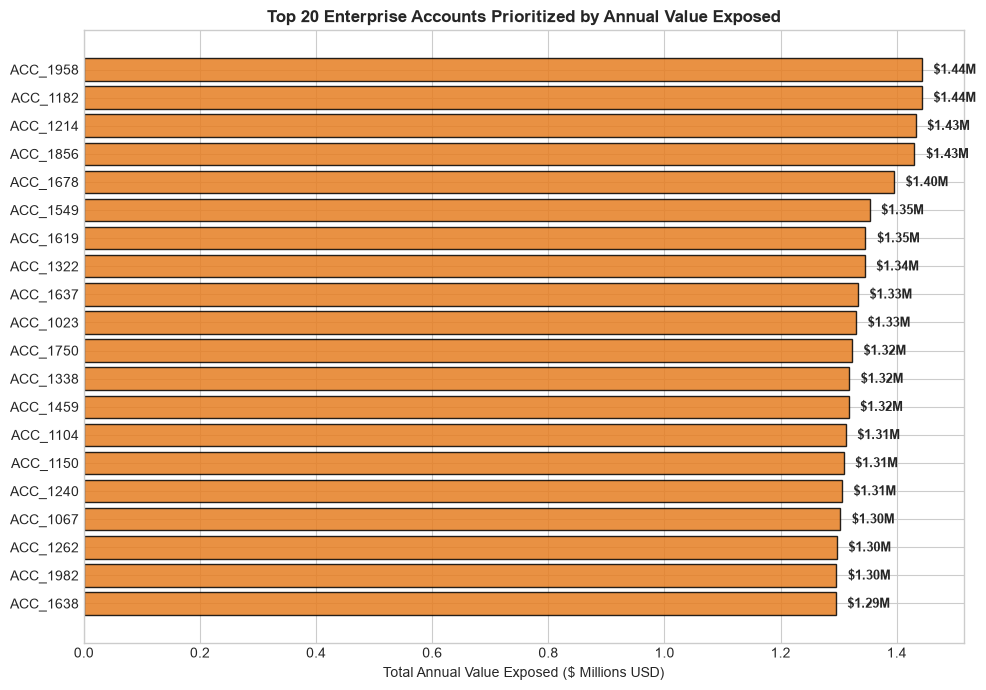

In [12]:
plt.figure(figsize=(10, 7))
top20_plot = top20_df.sort_values(by="value_exposed", ascending=True)

plt.barh(top20_plot["account_id"], top20_plot["value_exposed"] / 1e6, color="#e67e22", edgecolor="black", alpha=0.85)
plt.xlabel("Total Annual Value Exposed ($ Millions USD)")
plt.title("Top 20 Enterprise Accounts Prioritized by Annual Value Exposed")

for i, val in enumerate(top20_plot["value_exposed"] / 1e6):
    plt.text(val + 0.02, i, f"${val:.2f}M", va="center", fontsize=9, fontweight="bold")

plt.tight_layout()
plt.show()


## 8. Non-Causal Intervention Break-Even Analysis

**Question:** What reduction in churn probability or value exposed is required to justify proactive retention interventions costing $C = \$5,000$ or $C = \$10,000$?

*Caveat:* This analysis is strictly a non-causal break-even hurdle calculation.


In [13]:
from src.phase3_financial import compute_intervention_break_even

be_df = compute_intervention_break_even(top20_df, costs=[5000.0, 10000.0])
be_df[['account_id', 'total_stated_profit', 'value_exposed', 'cost_5k', 'required_effectiveness_5k', 'break_even_churn_reduction_5k', 'cost_10k', 'required_effectiveness_10k', 'break_even_churn_reduction_10k']].head(10)


,account_id,total_stated_profit,value_exposed,cost_5k,required_effectiveness_5k,break_even_churn_reduction_5k,cost_10k,required_effectiveness_10k,break_even_churn_reduction_10k
0,ACC_1958,8717397.0,1443102.33,5000.0,0.0209,0.0035,10000.0,0.0419,0.0069
1,ACC_1182,8384947.0,1443037.44,5000.0,0.0201,0.0035,10000.0,0.0403,0.0069
2,ACC_1214,8777439.0,1432366.24,5000.0,0.0214,0.0035,10000.0,0.0428,0.0070
3,ACC_1856,8951801.0,1430497.79,5000.0,0.0219,0.0035,10000.0,0.0437,0.0070
4,ACC_1678,8548188.0,1395180.44,5000.0,0.0219,0.0036,10000.0,0.0439,0.0072
5,ACC_1549,8523684.0,1353137.77,5000.0,0.0232,0.0037,10000.0,0.0465,0.0074
6,ACC_1619,8460724.0,1346127.55,5000.0,0.0233,0.0037,10000.0,0.0467,0.0074
7,ACC_1322,8372516.0,1344650.06,5000.0,0.0231,0.0037,10000.0,0.0463,0.0074
8,ACC_1637,7934496.0,1333013.17,5000.0,0.0223,0.0038,10000.0,0.0446,0.0075
9,ACC_1023,8229282.0,1329874.52,5000.0,0.0232,0.0038,10000.0,0.0465,0.0075


## 9. Summary & Methodological Limitations

### Executive Summary
1. **Corporate Assumption Fails Back-Test:** Observed annual churn across 1,884 labelled arrays is **15.82%**, rejecting Everpure's 5.0% planning assumption across every customer cohort ($p < 0.05$ after Holm correction).
2. **Forecast Debt of \$1.957 Billion:** Adjusting stated 15-year lifecycle profit (\$4.306B) for observed customer retention behavior reveals a \$1.957B valuation overstatement (45.46% gap).
3. **Annual Value Exposed of \$681.51 Million:** The immediate 12-month value at risk is concentrated in large enterprise accounts (Top 20 accounts account for over \$27M in annual value exposed).

### Methodological Limitations (Interview-Defensible Honesty)
1. **12-Month Target Horizon:** Ground truth data only covers single-year churn.
2. **No Supervised 15-Year Model:** 15-year renewal predictions cannot be trained from cross-sectional data.
3. **Scenario-Based 15-Year Outputs:** Multi-year projections are geometric decay scenarios, not forecasts.
4. **Weak Individual Discrimination:** ROC-AUC is ~0.50–0.51; individual ranking should not be oversold.
5. **Baseline Miscalibration as Primary Finding:** The primary value is macro calibration correction rather than individual prediction.
6. **Forecast Debt Definition:** Represents an estimated model-based valuation gap, not realized cash loss.
7. **Historical vs. Forward Profit:** `historical_15yr_net_profit_usd` is a backward-looking economic figure.
8. **Heuristic Expansion Scoring:** Expansion scores are business rule combinations, not probabilities.
9. **Non-Causal Intervention Hurdle:** Break-even analysis is an ROI threshold, not an uplift experiment.
10. **Holdout Rows Unused:** The 116 unlabelled rows are excluded from empirical back-testing.
11. **Cross-Sectional Grouped CV:** Back-testing evaluates out-of-fold generalization, not temporal forward testing.
